---

NDS-Mini

---

In [1]:
# autoload
%load_ext autoreload
%autoreload 2

# Load PGL libraries and start a PGL window
from pgl import pgl
from pgl.pglImage import pglImageDatabase, pglImage
from pgl.pglMessages import pglMessages
from pgl.pglExperiment import pglTask, pglExperiment
from pgl.pglParameter import pglParameter, pglParameterBatch
from pgl.pglImage import pglImageFileNSDMini, pglImageFile
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio

pgl = pgl()

# close any existing windows
pgl.cleanUp()
nsdminiStimuliFilePath = "/Users/justin/proj/nsdmini/nsdmini_stimuli.hdf5"

================================ pglBase: init =================================
(pgl) mglMetal error log can be viewed in MacOS Console app by searching for PROCESS mglMetal or in a terminal with:
      log stream --level info --process mglMetal
(pgl) To search for something specifc, e.g. messages from mglMovie:
      log stream --predicate 'eventMessage CONTAINS "mglMovie"' --style syslog --level info
(pgl->pglBase:checkOS) Python version: 3.12.13 | packaged by conda-forge | (main, Mar  5 2026, 17:06:14) [Clang 19.1.7 ]
(pgl->pglBase:checkOS) Running on MacBook Pro (MacBookPro18,3) with macOS version: 26.6.2
(pgl->pglBase:checkOS) Apple M1 Pro Cores: 8 (6 Performance and 2 Efficiency) Memory: 32 GB
(pgl->pglBase:checkOS) GPU: Apple M1 Pro (Built-In) 14 cores, Metal 4 support
(pgl->pglBase:checkOS)    Color LCD [Main Display]: 3024 x 1964 Retina (Built-in Liquid Retina XDR Display) GammaTable size: 1024
(pgl->pglBase:__init__) Main library instance created
(pglBase:shutdownAll) Shutti

In [ ]:
pgl.settings()

---

NSD-mini task

---

In [ ]:
class pglNSDMiniTask(pglTask):
    
    ########################
    def __init__(self, pgl, runNum=None, tr=1.5):
        super().__init__(pgl)
        
        # set task parameters, these will automatically be saved in the settings file
        self.settings.taskName = "NSD-mini"
        
        # is main task for analysis code
        self.settings.isMainTask = True
        self.settings.trialPrintNewline = False
        
        # fixed parameters, these will automatically be saved in the settings file
        self.settings.config.imageWidth = 8.4
        self.settings.config.imageCenterX = 0
        self.settings.config.imageCenterY = 2.5
        self.settings.config.stimuliFilePath = "/Users/justin/proj/nsdmini/nsdmini_stimuli.hdf5"
        self.settings.config.expdesignFilePath = "/Users/justin/proj/nsdmini/nsdmini_expdesign.mat"
        self.settings.config.tr = tr
        self.settings.config.fixationSize = 0.6
        
        # trial counts
        self.settings.config.startBlankTrials = 5
        self.settings.config.nImagesPerRun = 103
        self.settings.config.nBlanksPerRun = 6
        self.settings.config.endBlankTrials = 6
        
        self.settings.config.minContinuousBlockLen = 12
        self.settings.config.maxContinuousBlockLen = 19
        
        # segment 0 is image display, segment 1 is blank
        self.settings.seglen = [2, 0.8]
        self.settings.waitUntilVolumeTrigger = [False, True]
        #self.settings.seglen = [0.2, 0.1]

        # import image database and NSD Mini class for handling h5 file
        from pgl.pglImage import pglImageDatabase, pglImageFileNSDMini
        import scipy.io as sio
        
        # initilize the image databse
        self.stimulusDatabase = pglImageDatabase(
            dataPath=self.settings.config.stimuliFilePath,
            stimulusFileClass=pglImageFileNSDMini
        )
        
        # get the stimulus ordering (use 0 based indexing)
        expdesign = sio.loadmat(self.settings.config.expdesignFilePath, simplify_cells=True)
        self.settings.config.masterOrdering = expdesign['masterordering']-1
        
        # set the runNum, if this is None, it will automatically set it based on the last run
        self.settings.config.runNum = runNum
        # add parameter for image number
        #imageNumParameter = pglParameterBatch('imageNum',np.arange(p['nImages']),batchSize=p['nImagesPerTrial'], catchTrialEvery=p['catchTrialEvery'], catchBatchEvery=p['catchBatchEvery'])
        #self.addParameter(imageNumParameter)

    ########################
    # configure
    ########################
    def configure(self, e):
        import math

        # Keep textures on the task, not in serialized settings/state/data.
        self._images = {}
        self._currentStimulusTrial = None
        self._currentImage = None

        # Initialize fixation and response state.
        self.state.fixColor = [1, 1, 1]
        self.state.gotResponse = False

        # get the last run
        if self.settings.config.runNum is None:
            lastRun = e.getLastRun(task=self)
            if lastRun is not None:
                self.settings.config.runNum = lastRun.settings.config.runNum+1
            else:
                self.settings.config.runNum = 0
        pglMessages.print(f"runNum: {self.settings.config.runNum}", messageType="experiment")
            
        # get the image ordering for this run
        trialOrder = self.makeTrialOrder(startImage = self.settings.config.nImagesPerRun*self.settings.config.runNum, seed=42+self.settings.config.runNum)
        self.stimulusDatabase.setTrialOrder(trialOrder)

        # compute number of trials
        self.settings.nTrials = len(trialOrder)
        
        # print trial info
        print(trialOrder)
        print(f"nTrials={self.settings.nTrials:.0f} nVols={self.settings.nTrials*2+1:.0f} runLen={self.settings.nTrials * math.ceil(sum(self.settings.seglen) / self.settings.config.tr) * self.settings.config.tr}s")
        print("~="*50)


        # preload images
        # Create one texture per unique image used in this run; skip blanks.
        for trialNum in range(self.stimulusDatabase.nTrials):
            trial = self.stimulusDatabase.getTrial(trialNum)
            if trial.isBlank or trial.stimulusNum in self._images: continue

            # Accessing trial.img loads and caches its PIL image.
            self._images[trial.stimulusNum] = self.pgl.imageCreate(np.array(trial.img))

        self.stimulusDatabase.startRun()

    ########################
    # startSegment
    ########################
    def startSegment(self, startTime):
        '''
        Start a segment
        '''
        super().startSegment(startTime)
        if self.state.currentSegment != 0: return

        # Get the stimulus trial corresponding to this task trial.
        trial = self.stimulusDatabase.getTrial(self.state.currentTrial)
        if trial is not self.stimulusDatabase.nextTrial():
            pglMessages.warning("Task trial and stimulus sequence are out of sync")

        if trial.isBlank:
            pglMessages.print("Blank trial", messageType="experiment")
        else:
            pglMessages.print(f"Stimulus trial {trial.stimulusNum}", messageType="experiment")
            
        self._currentStimulusTrial = trial
        self._currentImage = None if trial.isBlank else self._images[trial.stimulusNum]

        # Reset response and fixation state for this presentation.
        self.state.gotResponse = False
        self.state.fixColor = [1, 1, 1, 0.5]

    ########################
    # endTrial
    ########################
    def endTrial(self, endTime):
        '''
        Record completion only after all segments of this trial finish.
        '''
        super().endTrial(endTime)
        trial = self._currentStimulusTrial
        if trial is None: return

        self.stimulusDatabase.completeTrial(trial.trialId)

        self._currentStimulusTrial = None
        self._currentImage = None

    ########################
    # updateScren
    ########################
    def updateScreen(self):
        '''
        update the screen
        '''
        # Clear the previous image, including during blanks and segment 1.
        # This task owns background clearing; coordinate this if other tasks draw too.
        self.pgl.clearScreen(0.5)

        if self.state.currentSegment == 0 and self._currentImage is not None:
            self._currentImage.display(x=self.settings.config.imageCenterX, y=self.settings.config.imageCenterY, width=self.settings.config.imageWidth)

        # draw fixation cross
        self.pgl.fixationABC(x=self.settings.config.imageCenterX, y=self.settings.config.imageCenterY, size=self.settings.config.fixationSize, color=self.state.fixColor, backgroundColor=0)

    ########################
    # handleSubjectResponse
    ########################
    def handleSubjectResponse(self, response, updateTime):
        '''
        Handle the subject response. Response will come in as an integer
        value of what button was pressed. The order of buttons is set
        in pgl.settings() in the field "responseKeys"
        '''
        # already received a response
        if self.state.gotResponse: return None
        if self._currentStimulusTrial is None: return None

        # mark that we got a response
        self.state.gotResponse = True

        # Count earlier image trials, excluding inserted blanks, to locate this
        # presentation in the master sequence. Do not include the current image.
        trial = self._currentStimulusTrial
        correct = False
        if not trial.isBlank:
            precedingImages = sum(
                not previousTrial.isBlank
                for previousTrial in self.stimulusDatabase.trials[:trial.trialNum]
            )
            masterIndex = self.settings.config.startImage + precedingImages
            earlierImages = np.asarray(self.settings.config.masterOrdering)[:masterIndex]
            correct = bool(np.any(earlierImages == trial.stimulusNum))

        # A button press is correct for a repeated image, incorrect otherwise.
        self.state.fixColor = [0,1,0,0.5] if correct else [1,0,0,0.5]

        # return response type
        return correct
    
    ########################
    # makeTrialOrder
    ########################
    def makeTrialOrder(self, startImage=0, seed=None):
        '''
        Each run consists of 15-s blank + (103 stimulus trials + 6 blank trials) * 3-s + 18-s blank = 360 s.
        103*10 = 1030 stimulus trials.
        Each run has 120 trials (but only 103 are stimulus trials).
        1030 stimulus trials corresponds to the 515 images being shown 2 times.
        For the central 103 stimulus trials, blank trials are placed in between these trials such that the minimum continuous duration
        of stimulus trials is 36 s (12 trials) and the maximum continuous duration of stimulus trials is 57 s (19 trials).

        from self.settings.config uses:

            nImagesPerRun
            startBlankTrials
            endBlankTrials
            nBlanksPerRun
            minContinuousBlockLen
            maxContinuousBlockLen
            masterOrdering

        '''
        rng = np.random.default_rng(seed)
        nBlocks = self.settings.config.nBlanksPerRun + 1

        # Check that the requested images fit within the block-length limits.
        if not nBlocks * self.settings.config.minContinuousBlockLen <= self.settings.config.nImagesPerRun <= nBlocks * self.settings.config.maxContinuousBlockLen:
            pglMessages.warning(f"{self.settings.config.nImagesPerRun} images cannot fit into {nBlocks} blocks of {self.settings.config.minContinuousBlockLen}–{self.settings.config.maxContinuousBlockLen} images")
            return None
        if startImage < 0 or startImage + self.settings.config.nImagesPerRun > len(self.settings.config.masterOrdering):
            pglMessages.warning("Not enough images in masterOrdering for the requested slice")
            return None

        # get image numbers from masterOrdering
        selectedImages = np.asarray(self.settings.config.masterOrdering)[startImage:startImage + self.settings.config.nImagesPerRun]

        # Start every block at its minimum, then randomly distribute remaining images.
        blockLengths = np.full(nBlocks, self.settings.config.minContinuousBlockLen, dtype=int)
        for _ in range(self.settings.config.nImagesPerRun - blockLengths.sum()):
            blockLengths[rng.choice(np.flatnonzero(blockLengths < self.settings.config.maxContinuousBlockLen))] += 1

        # Split at block boundaries, inserting one blank between blocks.
        blocks = np.split(selectedImages, np.cumsum(blockLengths)[:-1])
        trialOrdering = [-1] * self.settings.config.startBlankTrials
        for blockNum, block in enumerate(blocks):
            if blockNum > 0: trialOrdering.append(-1)
            trialOrdering.extend(block.tolist())

        # Append the ending blank trials.
        trialOrdering.extend([-1] * self.settings.config.endBlankTrials)

        self.settings.config.startImage = startImage
        
        return np.asarray(trialOrdering, dtype=int)

In [39]:
subjectID='s00000'
e = pglExperiment(pgl,experimentName='nsd-mini',subjectID=subjectID)
nsdMiniTask = pglNSDMiniTask(pgl, tr=1.5, runNum=None)
e.addTask(nsdMiniTask)

(pglImageDatabase:__init__) Found 515 images in /Users/justin/proj/nsdmini/nsdmini_stimuli.hdf5


runNum: 0
[ -1  -1  -1  -1  -1 134 502 511 428 194 448 402 506 307 466 424 201 194
 217 454 346  -1  27 306 322 306 252 428 258 406 352 201 111  87 427  -1
 382 134 239 346 222 462 454 252 323 406 511 494  -1 466 136 302 296 475
  27 324 197 436  71 239 120  82 390 300 376  -1  86  87  21 240   4 222
 415 280 486 407 448 179 436 257  -1  85 303 271 320  89 280 376 313  13
 422 494 476 309 206  71 167 407 513  -1  82 120 486 304 136 431  24 344
 502 167 206 158 238 285  -1  -1  -1  -1  -1  -1]
nTrials=120 nVols=241 runLen=180.0s
~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=~=
(pglExperiment:_run) Manual pre-start ended after 0 volumes.
(pglExperiment:_run) Ignored 0 initial volumes.
(pglExperiment:_run) Experiment started.
(pglExperiment:startPhase) Starting phase: 1/1
(NSD-mini) Trial 1:  Blank trial
(NSD-mini) Trial 2:  Blank trial
(NSD-mini) Trial 3:  Blank trial
(NSD-mini) Trial 4:  Blank trial
(NSD-mini) Trial 5:  Blank trial
(NS

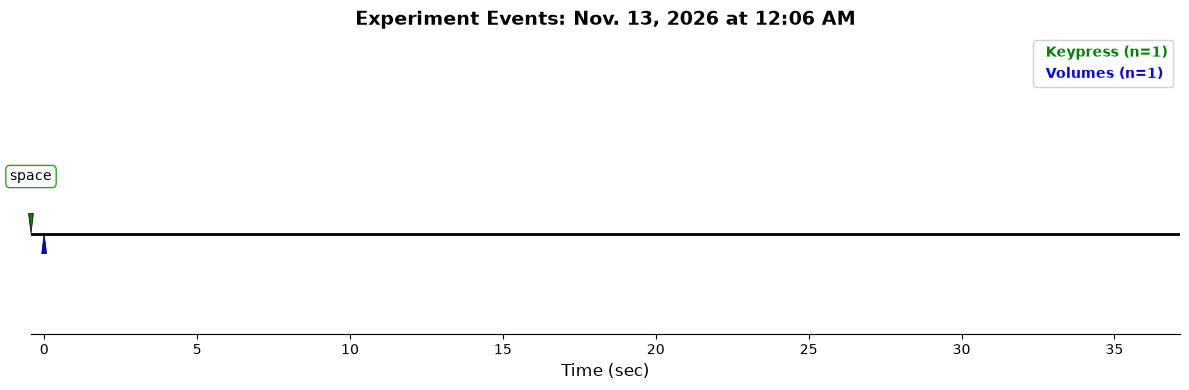

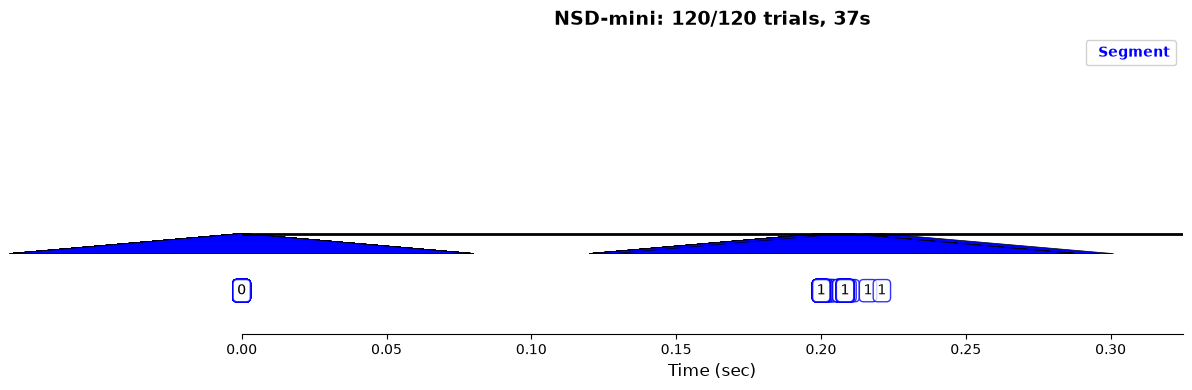

In [40]:
e.initScreen()
e.run()
e.display()